# Supplementary Figure S17: stability of the ranked list of TSSs

Source data from `export/export_figS17.py` and `export/export_figS17_cohen_d.py` (cohort `no_deep`, both
tasks). For each of the 14,221 TSSs, Cohen's *d* (cancer − healthy) of the row-z-scored Griffin
coverage-difference feature (GD) ranks the list.

* *Stability.* The list rebuilt on each of the ten outer-training sets of the task's nested run (fold
  vs full; the 45 fold pairs), and two references: two disjoint stratified halves of the cohort (50
  splits) and permuted labels (20 permutations).
* *Fitted weights.* The ten fold winners refitted from the stored configuration on the stored training
  rows (each must reproduce its stored held-out AUROC): elastic-net logistic regression (PANCAN) and
  linear SVM (BRCA/CRC) coefficients on the standardized selected columns.

Sign convention: positive = GD higher in cancer plasma (a deeper nucleosome-depleted dip).

In [1]:
import os, json

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# --- cohort switch ------------------------------------------------------------------
COHORT = os.environ.get("FIG_COHORT", "no_deep")   # no_deep is the default cohort
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)


def data_path(name):
    p = os.path.join(_DATA, name)
    assert os.path.exists(p), f"{p} missing - run COHORT_VARIANT={COHORT} python export/export_figS17.py"
    return p


def out_path(name):
    return os.path.join(_OUT, name)


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

TASKS = ["brca_crc", "pancan"]
TASK_LABELS = {"brca_crc": "BRCA/CRC versus healthy", "pancan": "Pan-cancer versus healthy"}
TASK_COLORS = {"brca_crc": "#0173B2", "pancan": "#DE8F05"}
COMP_LABELS = {"fold_vs_full": "fold list vs full list", "fold_vs_fold": "fold vs fold (share ~80 % of samples)",
               "half_vs_half": "disjoint halves (sampling noise)", "permuted_vs_full": "permuted labels (chance)",
               "weight_fold_vs_fold": "fitted weights, fold vs fold"}
COMP_COLORS = {"fold_vs_full": "#0173B2", "fold_vs_fold": "#56B4E9", "half_vs_half": "#029E73",
               "permuted_vs_full": "0.55", "weight_fold_vs_fold": "#D55E00"}
TOP_K = [100, 250, 500, 1000, 2500, 5000, 10000]

eff = {t: pd.read_csv(data_path(f"figS17_tss_effects_{t}.csv")) for t in TASKS}
stab = pd.read_csv(data_path("figS17_stability.csv"))
folds = pd.read_csv(data_path("figS17_folds.csv"))
# The assembled figure ranks the TSSs by Cohen's d (export_figS17_cohen_d.py): the statistic of the gene-set
# analyses. Sections 1-6 below still show the pipeline's own ranking (difference in means).
stab_d = pd.read_csv(data_path("figS17_stability_cohen_d.csv"))
stab_d = stab_d[stab_d["statistic"] == "cohen_d"]
with open(data_path("figS17_summary_cohen_d.json")) as fh:
    summary_d = {t: v["cohen_d"] for t, v in json.load(fh).items()}
tss_d = pd.read_csv(data_path("figS17_tss_cohen_d.csv"))
for t in TASKS:
    m = eff[t].merge(tss_d[tss_d["task"] == t].drop(columns="task").rename(columns={"cohen_d": "cohen_d_check"}), on="bed_row", validate="1:1")
    assert len(m) == len(eff[t]) and np.allclose(m["cohen_d"], m["cohen_d_check"], atol=1e-6), t
    eff[t] = m.drop(columns="cohen_d_check")
with open(data_path("figS17_summary.json")) as fh:
    summary = json.load(fh)
for t in TASKS:
    s = summary[t]
    print(f"{TASK_LABELS[t]}: {s['n_samples']} samples ({s['n_healthy']} healthy, {s['n_cancer']} cancer), {s['n_tss']} TSSs; "
          f"k per fold {s['k_per_fold']}; selected sets match the stored run: {s['selected_sets_match_stored']}; "
          f"refit AUROC within {s['refit_auc_max_abs_diff']:.3f} of the stored values")

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


BRCA/CRC versus healthy: 244 samples (164 healthy, 80 cancer), 14221 TSSs; k per fold [10000, 10000, 10000, 10000, 15000, 15000, 10000, 10000, 10000, 15000]; selected sets match the stored run: True; refit AUROC within 0.000 of the stored values
Pan-cancer versus healthy: 367 samples (164 healthy, 203 cancer), 14221 TSSs; k per fold [15000, 10000, 15000, 10000, 10000, 10000, 15000, 15000, 10000, 15000]; selected sets match the stored run: True; refit AUROC within 0.000 of the stored values


## 1. Checks: the replicated lists are the model's lists

Each fold's top-*k* set by |mean difference| on its outer-training rows must equal the stored
`selected_gene_indices`, and the refitted fold winner must reproduce the stored held-out AUROC.

In [2]:
show = folds[["task", "fold", "k", "selection_type", "n_selected", "classifier", "stored_test_auc", "refit_test_auc",
              "own_ranking_matches_stored", "jaccard_meandiff_vs_stored_same_k", "n_weights_nonzero",
              "spearman_signed_vs_full", "jaccard_selected_vs_full_same_k"]].copy()
show["auc_diff"] = (show["refit_test_auc"] - show["stored_test_auc"]).round(4)
display(show.round(3))
assert show["own_ranking_matches_stored"].all(), "a fold's selected loci differ from the stored run"
assert (show["auc_diff"].abs() < 0.02).all(), "a refit does not reproduce its stored AUROC"
print("all ten folds of both tasks: the replicated selection equals the stored run; refits reproduce the stored AUROCs")
for t in TASKS:
    f = folds[folds["task"] == t]
    print(f"{TASK_LABELS[t]}: ranking function chosen per fold {f['selection_type'].value_counts().to_dict()}; "
          f"at k = 10,000 the fold's own ranking and the mean-difference ranking select sets with Jaccard "
          f"{f.loc[f['k'] < 14221, 'jaccard_meandiff_vs_stored_same_k'].round(2).tolist()}")

,task,fold,k,selection_type,n_selected,classifier,stored_test_auc,refit_test_auc,own_ranking_matches_stored,jaccard_meandiff_vs_stored_same_k,n_weights_nonzero,spearman_signed_vs_full,jaccard_selected_vs_full_same_k,auc_diff
0,brca_crc,1,10000,fold_change,10000,Support Vector Machine,0.912,0.912,True,0.765,10000,0.971,0.706,0.0
1,brca_crc,2,10000,p_value,10000,Support Vector Machine,0.963,0.963,True,0.848,10000,0.968,0.775,0.0
2,brca_crc,3,10000,fold_change,10000,Support Vector Machine,0.985,0.985,True,0.771,10000,0.968,0.715,0.0
3,brca_crc,4,10000,fold_change,10000,Support Vector Machine,1.000,1.000,True,0.772,10000,0.962,0.703,0.0
4,brca_crc,5,15000,mean_diff,14221,Support Vector Machine,0.922,0.922,True,1.000,14221,0.965,1.000,0.0
5,brca_crc,6,15000,mean_diff,14221,Support Vector Machine,1.000,1.000,True,1.000,14221,0.966,1.000,0.0
6,brca_crc,7,10000,fold_change,10000,Support Vector Machine,0.969,0.969,True,0.762,10000,0.969,0.704,0.0
7,brca_crc,8,10000,fold_change,10000,Support Vector Machine,0.984,0.984,True,0.765,10000,0.966,0.702,0.0
8,brca_crc,9,10000,fold_change,10000,Support Vector Machine,0.945,0.945,True,0.763,10000,0.969,0.705,0.0
9,brca_crc,10,15000,mean_diff,14221,Support Vector Machine,0.977,0.977,True,1.000,14221,0.969,1.000,0.0


all ten folds of both tasks: the replicated selection equals the stored run; refits reproduce the stored AUROCs
BRCA/CRC versus healthy: ranking function chosen per fold {'fold_change': 6, 'mean_diff': 3, 'p_value': 1}; at k = 10,000 the fold's own ranking and the mean-difference ranking select sets with Jaccard [0.76, 0.85, 0.77, 0.77, 0.76, 0.77, 0.76]
Pan-cancer versus healthy: ranking function chosen per fold {'mean_diff': 8, 'p_value': 2}; at k = 10,000 the fold's own ranking and the mean-difference ranking select sets with Jaccard [1.0, 0.85, 1.0, 1.0, 0.85]


## 2. Summary of the numbers

In [3]:
keys = ["spearman_signed_fold_vs_full_median", "spearman_signed_fold_vs_fold_median", "spearman_signed_half_vs_half_median",
        "spearman_signed_permuted_median", "jaccard_top100_fold_vs_fold_median", "jaccard_top100_half_vs_half_median",
        "jaccard_top1000_fold_vs_full_median", "jaccard_top1000_fold_vs_fold_median", "jaccard_top1000_half_vs_half_median",
        "jaccard_top1000_permuted_median", "jaccard_top1000_chance",
        "weight_spearman_both_nonzero_fold_vs_fold_median", "weight_jaccard_top100_fold_vs_fold_median",
        "weight_jaccard_top1000_fold_vs_fold_median"]
display(pd.DataFrame({TASK_LABELS[t]: {k: summary[t][k] for k in keys} for t in TASKS}).round(3))

,BRCA/CRC versus healthy,Pan-cancer versus healthy
spearman_signed_fold_vs_full_median,0.968,0.971
spearman_signed_fold_vs_fold_median,0.929,0.938
spearman_signed_half_vs_half_median,0.278,0.342
spearman_signed_permuted_median,-0.015,0.001
jaccard_top100_fold_vs_fold_median,0.460,0.460
jaccard_top100_half_vs_half_median,0.124,0.117
jaccard_top1000_fold_vs_full_median,0.667,0.684
jaccard_top1000_fold_vs_fold_median,0.542,0.564
jaccard_top1000_half_vs_half_median,0.082,0.098
jaccard_top1000_permuted_median,0.066,0.057


## 3. Source-data tables

`data/no_deep/figS17_tss_effects_{brca_crc,pancan}.csv` give, for every TSS: coordinates, gene, strand
and GC; the signed mean difference and its rank; Cohen's *d*, the per-TSS AUROC, Welch *p* and BH *q*;
the mean and s.d. of the effect over the ten outer-training sets and the mean rank; the number of folds
in which the TSS was selected (fold's own *k* and ranking, identical to the stored run), selected under
the mean-difference ranking, and in the top 1,000; the mean and s.d. of the fitted weight and the number
of folds with a non-zero weight. `figS17_stability.csv` and `figS17_folds.csv` hold every pairwise
comparison and the per-fold checks.

The top of the list is dominated by multi-copy loci (segmental duplications), whose coverage features
depend on read mapping; treat them with care in set-level analyses.

## Group means of opposite sign

The features are z-scored within each sample, so a TSS's healthy and cancer group means can have
opposite signs. The fold-change ranking functions (absolute log2 fold change, and fold change
weighted by the p-value) are undefined there and give the TSS a score of zero.

In [4]:
for t in TASKS:
    e = eff[t]
    opp = (e["mean_healthy"] * e["mean_cancer"] < 0)
    assert abs(opp.mean() - summary[t]["share_opposite_sign_group_means"]) < 1e-12
    print(f"{t}: {int(opp.sum())} of {len(e)} TSSs ({opp.mean():.1%}) have group means of opposite sign")

brca_crc: 778 of 14221 TSSs (5.5%) have group means of opposite sign
pancan: 624 of 14221 TSSs (4.4%) have group means of opposite sign


<!-- assembled-figure -->
## 4. Figure S17 (assembled)

(a, b) Spearman correlation of Cohen's *d* between two rankings, per task: fold vs full list, fold vs
fold, two disjoint halves and permuted labels. (c, d) Each outer fold orders all 14,221 TSSs by Cohen's
*d* or by the size of its fitted coefficient (0 if the fold did not select the TSS); the top *k* TSSs of
two orderings are compared (Jaccard: shared / all distinct TSSs) for two outer folds, two disjoint halves
and permuted labels; the Spearman values in the legend compare the complete orderings.

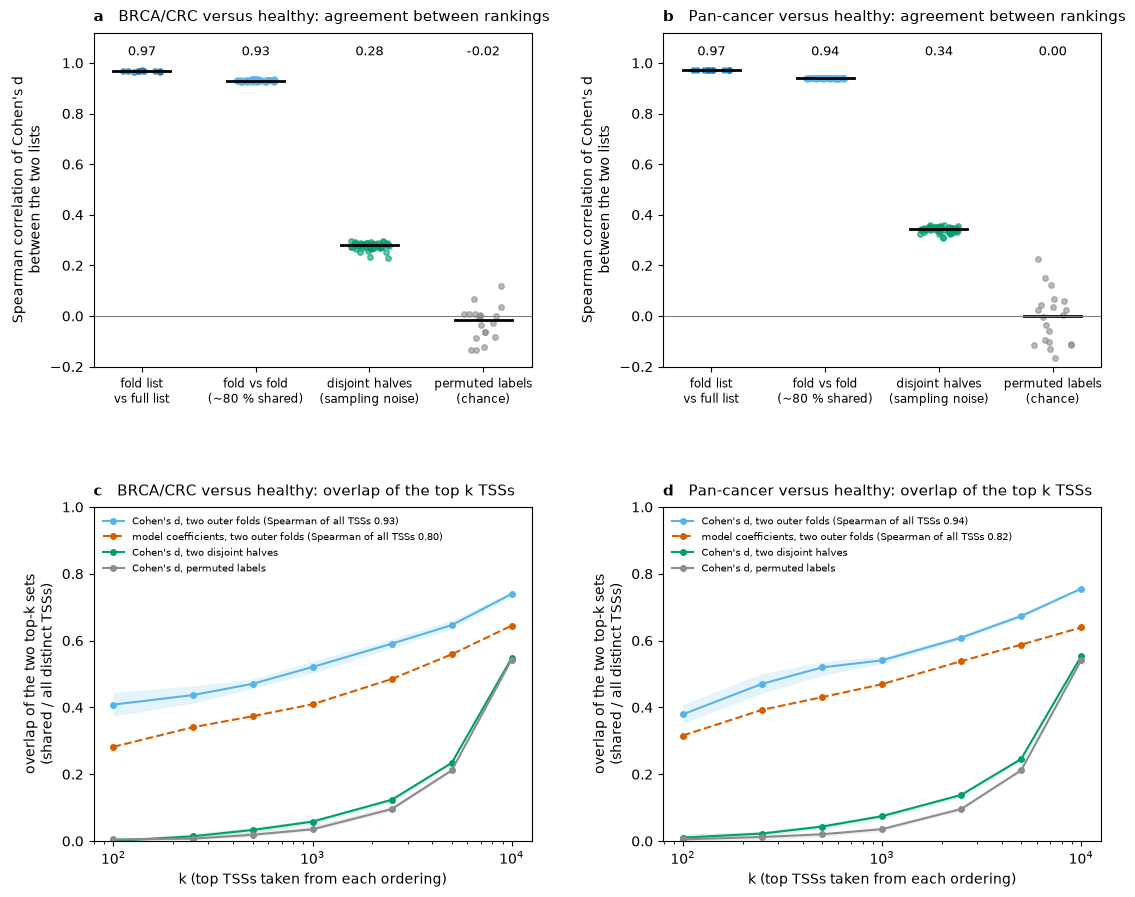

Figure S17 written to output\no_deep\figS17.png and .pdf


In [5]:
def ttl(ax, letter, text, size=11):
    ax.set_title(f"$\\bf{{{letter}}}$   {text}", loc="left", fontsize=size, pad=8)

comps4 = ["fold_vs_full", "fold_vs_fold", "half_vs_half", "permuted_vs_full"]
FIG_COMP_LABELS = {"fold_vs_full": "fold list\nvs full list", "fold_vs_fold": "fold vs fold\n(~80 % shared)", "half_vs_half": "disjoint halves\n(sampling noise)", "permuted_vs_full": "permuted labels\n(chance)"}
fig = plt.figure(figsize=(13, 10.5))
gs = fig.add_gridspec(2, 2, hspace=0.42, wspace=0.3)
# --- a, b: whole-list agreement per task ----------------------------------------------------
for col, t in enumerate(TASKS):
    ax = fig.add_subplot(gs[0, col]); S = stab_d[stab_d["task"] == t]
    for i, c in enumerate(comps4):
        v = S[(S["comparison"] == c) & (S["metric"] == "spearman_signed")]["value"].to_numpy()
        jit = (np.random.default_rng(1).random(len(v)) - 0.5) * 0.35
        ax.plot(i + jit, v, "o", color=COMP_COLORS[c], alpha=0.6, markersize=4)
        ax.plot([i - 0.25, i + 0.25], [np.median(v)] * 2, color="black", lw=2)
        ax.text(i, 1.03, f"{np.median(v):.2f}", ha="center", fontsize=9)
    ax.set_xticks(range(len(comps4))); ax.set_xticklabels([FIG_COMP_LABELS[c] for c in comps4], fontsize=8.5)
    ax.set_ylim(-0.2, 1.12); ax.axhline(0, color="0.5", lw=0.8); ax.set_ylabel("Spearman correlation of Cohen's d\nbetween the two lists")
    ttl(ax, "ab"[col], f"{TASK_LABELS[t]}: agreement between rankings")
# --- c, d: overlap of the top-k sets, effect list vs fitted weights -------------------------
for col, t in enumerate(TASKS):
    ax = fig.add_subplot(gs[1, col]); S = stab[stab["task"] == t]; SD = stab_d[stab_d["task"] == t]
    s = summary[t]; sd_ = summary_d[t]
    for c, ls, lab in [("fold_vs_fold", "-", f"Cohen's d, two outer folds (Spearman of all TSSs {sd_['spearman_signed_fold_vs_fold_median']:.2f})"),
                       ("weight_fold_vs_fold", "--", f"model coefficients, two outer folds (Spearman of all TSSs {s['weight_spearman_signed_fold_vs_fold_median']:.2f})"),
                       ("half_vs_half", "-", "Cohen's d, two disjoint halves"), ("permuted_vs_full", "-", "Cohen's d, permuted labels")]:
        S_ = S if c == "weight_fold_vs_fold" else SD
        med = [S_[(S_["comparison"] == c) & (S_["metric"] == f"jaccard_top{k}")]["value"].median() for k in TOP_K]
        lo = [S_[(S_["comparison"] == c) & (S_["metric"] == f"jaccard_top{k}")]["value"].quantile(0.1) for k in TOP_K]
        hi = [S_[(S_["comparison"] == c) & (S_["metric"] == f"jaccard_top{k}")]["value"].quantile(0.9) for k in TOP_K]
        colr = COMP_COLORS[c]
        ax.plot(TOP_K, med, ls, marker="o", color=colr, markersize=4, label=lab)
        if c != "weight_fold_vs_fold":
            ax.fill_between(TOP_K, lo, hi, color=colr, alpha=0.15, linewidth=0)
    ax.set_xscale("log"); ax.set_ylim(0, 1); ax.set_xlabel("k (top TSSs taken from each ordering)"); ax.set_ylabel("overlap of the two top-k sets" + "\n" + "(shared / all distinct TSSs)")
    ax.legend(fontsize=7.5, frameon=False, loc="upper left")
    ttl(ax, "cd"[col], f"{TASK_LABELS[t]}: overlap of the top k TSSs")
fig.savefig(out_path("figS17.png"), dpi=200, bbox_inches="tight"); fig.savefig(out_path("figS17.pdf"), bbox_inches="tight")
plt.show()
print(f"Figure S17 written to {out_path('figS17.png')} and .pdf")